In [41]:
# 1. Import libraries
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import train_test_split


In [42]:
data = pd.read_csv(r"D:\Downloads\DL DATASET\MNIST\mnist_784_csv.csv")


In [43]:
# Separate pixel values from labels

# Separate pixels and labels
X = data.drop('class', axis=1).values
# Normalize pixel values between 0 and 1
X = X.astype('float32') / 255.0
print("Dataset shape:", X.shape)

Dataset shape: (70000, 784)


In [44]:
# 3. Split dataset into training and testing
X_train, X_test = train_test_split(
    X,
    test_size=0.2,
    random_state=42
)

In [52]:

# 4. Add noise to images
noise_factor = 0.3

X_train_noisy = X_train + noise_factor * np.random.randn(*X_train.shape)
X_test_noisy = X_test + noise_factor * np.random.randn(*X_test.shape)

# Clip values between 0 and 1
X_train_noisy = np.clip(X_train_noisy, 0, 1)
X_test_noisy = np.clip(X_test_noisy, 0, 1)


In [53]:
# 5. Build Autoencoder model
input_dim = X.shape[1]

# Input layer
input_layer = Input(shape=(input_dim,))

# Encoder
encoded = Dense(256, activation='relu')(input_layer)
encoded = Dense(128, activation='relu')(encoded)

# Decoder
decoded = Dense(256, activation='relu')(encoded)
decoded = Dense(input_dim, activation='sigmoid')(decoded)

# Create autoencoder
autoencoder = Model(input_layer, decoded)


In [54]:
# 6. Compile model
autoencoder.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='binary_crossentropy'
)

# Display model summary
autoencoder.summary()

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)           │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_15 (Dense)                     │ (None, 256)                 │         200,960 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_16 (Dense)                     │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_17 (Dense)                     │ (None, 256)                 │          33,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_18 (Dense)                     │ (None, 784)                 │         201,488 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 468,368 (1.79 MB)

 Trainable params: 468,368 (1.79 MB)

 Non-trainable params: 0 (0.00 B)

In [55]:
# 7. Train the model
history = autoencoder.fit(
    X_train_noisy,
    X_train,
    epochs=20,
    batch_size=256,
    shuffle=True,
    validation_data=(X_test_noisy, X_test)
)

Epoch 1/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 12s 43ms/step - loss: 0.2203 - val_loss: 0.1438
Epoch 2/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 9s 42ms/step - loss: 0.1282 - val_loss: 0.1179
Epoch 3/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 9s 42ms/step - loss: 0.1124 - val_loss: 0.1077
Epoch 4/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 9s 40ms/step - loss: 0.1046 - val_loss: 0.1024
Epoch 5/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 9s 42ms/step - loss: 0.1005 - val_loss: 0.0993
Epoch 6/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 9s 41ms/step - loss: 0.0976 - val_loss: 0.0966
Epoch 7/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 9s 42ms/step - loss: 0.0954 - val_loss: 0.0952
Epoch 8/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 7s 30ms/step - loss: 0.0938 - val_loss: 0.0940
Epoch 9/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 11s 52ms/step - loss: 0.0926 - val_loss: 0.0932
Epoch 10/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 13s 18ms/step - loss: 0.0915 - val_loss: 0.0917
Epoch 11/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 9s 41ms/step - loss: 0.0907 - val_loss: 0.0911
Epoch 12/20
219/219 ━━━━━━━━━━━━━━━━━━

In [56]:
# 11. Evaluate model
loss = autoencoder.evaluate(X_test_noisy, X_test)

print("Denoising Loss:", loss)

438/438 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0876
Denoising Loss: 0.08756420761346817


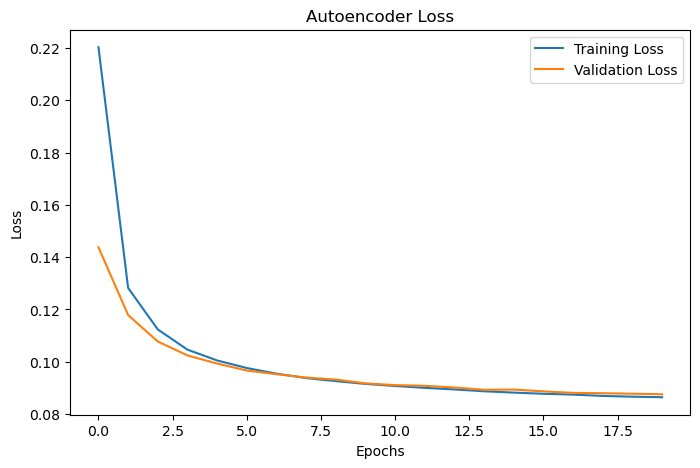

In [57]:
# 10. Plot training and validation loss
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title("Autoencoder Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 170ms/step


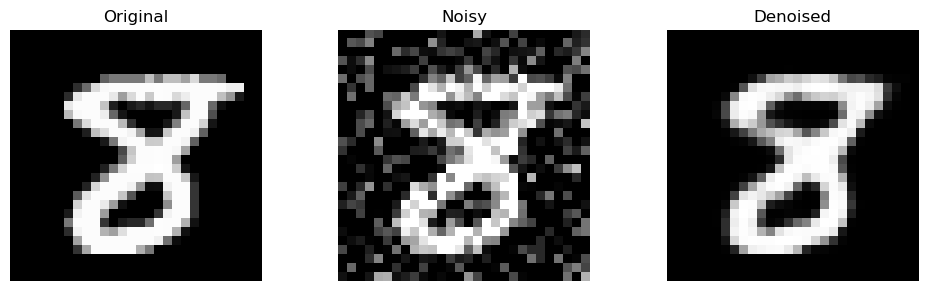

In [60]:

# 8. Predict denoised image
denoised_image = autoencoder.predict(X_test_noisy[:1])

# 9. Display one image
plt.figure(figsize=(10, 3))

# Original image
plt.subplot(1, 3, 1)
plt.imshow(X_test[0].reshape(28, 28), cmap='gray')
plt.title("Original")
plt.axis('off')

# Noisy image
plt.subplot(1, 3, 2)
plt.imshow(X_test_noisy[0].reshape(28, 28), cmap='gray')
plt.title("Noisy")
plt.axis('off')

# Denoised image
plt.subplot(1, 3, 3)
plt.imshow(denoised_image[0].reshape(28, 28), cmap='gray')
plt.title("Denoised")
plt.axis('off')

plt.tight_layout()
plt.show()
